# Прогнозирование стоимости недвижимости: продажа и аренда

Работа выполняется **отдельно для двух типов объявлений**:

- listing_type = 1 — продажа;
- listing_type = 2 — аренда.

Цена продажи и арендная плата имеют разный экономический смысл, поэтому одна модель не смешивает эти две задачи. Для каждого типа строится собственная модель, сравниваются Ridge, Decision Tree, Random Forest и Gradient Boosting, а затем выбранная модель проверяется на 20 объектах из test_real_estate_samples.csv.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [21]:
RANDOM_STATE = 42
TARGET = "price"
CURRENCY = "TRY"
SALE = 1
RENT = 2

## 1. Загрузка данных и первичный анализ

In [22]:
df = pd.read_csv("real_estate_data.csv", low_memory=False)
test_samples = pd.read_csv("test_real_estate_samples.csv", low_memory=False)

print("Основной датасет:", df.shape)
print("Тестовый файл:", test_samples.shape)

Основной датасет: (403487, 17)
Тестовый файл: (20, 17)


In [23]:
display(df.head())

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY


In [24]:
display(test_samples)

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,2+2,250.0,İzmir/Foça/Yeniköy,NaN,Yok,1600000.0,TRY
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,3+1,122.0,Tekirdağ/Çerkezköy/Kızılpınar,NaN,Yok,103600.0,TRY
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,1+0,1.0,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY
5,100,Konut,Yazlık,1/12/19,NaN,1,46,1,10,9,3+1,150.0,Mersin/Erdemli/Kargıpınarı,NaN,Fancoil,500000.0,TRY
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,4+1,134.0,Balıkesir/Burhaniye/Pelitköy,NaN,Fancoil,1000000.0,TRY
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,NaN,4,NaN,4+1,145.0,İzmir/Konak/Akın Simav,NaN,Kalorifer (Doğalgaz),650000.0,TRY
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,3+1,125.0,Muğla/Bodrum/Ortakentyahşi,NaN,Fancoil,2450000.0,TRY


In [25]:
print("Типы объявлений:")
print(df["listing_type"].value_counts(dropna=False))

Типы объявлений:
listing_type
1    287009
2    114236
3      2242
Name: count, dtype: int64


In [26]:
print("\nТипы объявлений в тесте:")
print(test_samples["listing_type"].value_counts(dropna=False))


Типы объявлений в тесте:
listing_type
1    10
2    10
Name: count, dtype: int64


In [28]:
print("\nВалюты:")
print(df["price_currency"].value_counts(dropna=False))


Валюты:
price_currency
TRY    400677
EUR       922
NaN       715
GBP       621
USD       552
Name: count, dtype: int64


listing_type определяет задачу:

- 1 — модель продажи;
- 2 — модель аренды.

Мы не смешиваем цены продажи и аренды в одной целевой переменной. При этом **вся исходная информация о рынке сохраняется для анализа**, а разделение выполняется непосредственно перед построением моделей.

## 2. Очистка данных

In [29]:
data = df.copy()

# Удаляем полностью пустой/неиспользуемый признак и дубликаты
for col in ["furnished", "type"]:
    if col in data.columns:
        data = data.drop(columns=col)

before_duplicates = len(data)
data = data.drop_duplicates().copy()

# Оставляем только строки с корректным типом объявления, ценой и валютой
data = data[data["listing_type"].isin([SALE, RENT])].copy()
data = data[data["price_currency"] == CURRENCY].copy()
data = data.dropna(subset=["price"]).copy()
data = data[data["price"] > 0].copy()

print("Удалено дубликатов:", before_duplicates - len(data))
print("Размер после базовой очистки:", data.shape)
print("\nПродажа:", (data["listing_type"] == SALE).sum())
print("Аренда:", (data["listing_type"] == RENT).sum())

Удалено дубликатов: 5088
Размер после базовой очистки: (398399, 15)

Продажа: 284468
Аренда: 113931


Цены продажи намного выше арендной платы. Если посчитать перцентили **по всему датасету**, почти все объекты аренды могут оказаться ниже общего 1-го перцентиля и исчезнуть.

Поэтому выбросы удаляются **отдельно внутри продажи и внутри аренды**. Это принципиально важно для корректного сравнения двух рынков.

In [30]:
def remove_extreme_prices(group):
    q_low = group["price"].quantile(0.01)
    q_high = group["price"].quantile(0.99)
    return group[group["price"].between(q_low, q_high)].copy()

sale_all = data[data["listing_type"] == SALE].copy()
rent_all = data[data["listing_type"] == RENT].copy()

sale_clean = remove_extreme_prices(sale_all)
rent_clean = remove_extreme_prices(rent_all)

print("Продажа: было", len(sale_all), "после фильтрации", len(sale_clean))
print("Аренда: было", len(rent_all), "после фильтрации", len(rent_clean))

Продажа: было 284468 после фильтрации 278806
Аренда: было 113931 после фильтрации 111782


## 3. Распределение цен продажи и аренды

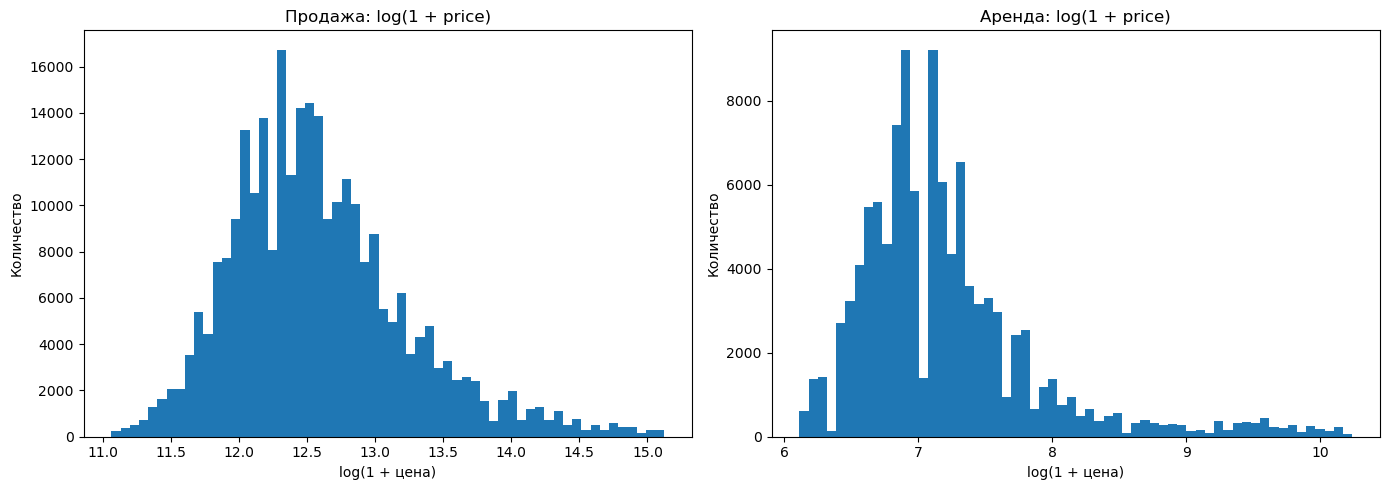

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(np.log1p(sale_clean["price"]), bins=60)
axes[0].set_title("Продажа: log(1 + price)")
axes[0].set_xlabel("log(1 + цена)")
axes[0].set_ylabel("Количество")

axes[1].hist(np.log1p(rent_clean["price"]), bins=60)
axes[1].set_title("Аренда: log(1 + price)")
axes[1].set_xlabel("log(1 + цена)")
axes[1].set_ylabel("Количество")

plt.tight_layout()
plt.show()

## 4. Feature Engineering

In [33]:
def make_features(dataframe, category_values=None):
    d = dataframe.copy()

    # Город и район из адреса
    address = d["address"].fillna("Unknown").astype(str)
    d["city"] = address.str.split("/").str[0].str.strip()
    d["district"] = address.str.split("/").str[1].str.strip().fillna("Unknown")

    # Комнаты: 3+1 -> rooms=3, living_rooms=1
    room_text = d["room_count"].fillna("").astype(str)
    d["rooms"] = pd.to_numeric(
        room_text.str.extract(r"^(\d+)")[0], errors="coerce"
    )
    d["living_rooms"] = pd.to_numeric(
        room_text.str.extract(r"\+(\d+)")[0], errors="coerce"
    ).fillna(0)

    # Возраст здания
    d["building_age_num"] = pd.to_numeric(
        d["building_age"].fillna("").astype(str).str.extract(r"(\d+)")[0],
        errors="coerce"
    )

    # Этажность
    d["total_floors_num"] = pd.to_numeric(
        d["total_floor_count"].fillna("").astype(str).str.extract(r"^(\d+)")[0],
        errors="coerce"
    )

    # Этаж объекта
    floor = d["floor_no"].fillna("").astype(str)
    d["floor_num"] = pd.to_numeric(
        floor.str.extract(r"^(\d+)")[0], errors="coerce"
    )
    d["is_penthouse"] = floor.str.contains(
        r"Çatı|En Üst", case=False, regex=True, na=False
    ).astype(int)
    d["is_garden"] = floor.str.contains(
        "Bahçe", case=False, regex=False, na=False
    ).astype(int)
    d["is_ground"] = floor.str.contains(
        r"Giriş|Zemin|Kot|Yüksek", case=False, regex=True, na=False
    ).astype(int)

    # Производные числовые признаки
    d["size"] = pd.to_numeric(d["size"], errors="coerce")
    d["size_per_room"] = d["size"] / (d["rooms"] + 1)
    d["is_new_building"] = (d["building_age_num"] <= 5).astype(int)
    d["floor_ratio"] = d["floor_num"] / (d["total_floors_num"] + 1)
    d["has_living_room"] = (d["living_rooms"] > 0).astype(int)

    # Категории: редкие значения объединяем в Other
    if category_values is None:
        top_subtypes = d["sub_type"].fillna("Unknown").value_counts().head(8).index
        top_heating = d["heating_type"].fillna("Unknown").value_counts().head(8).index
        top_cities = d["city"].fillna("Unknown").value_counts().head(30).index
        top_districts = d["district"].fillna("Unknown").value_counts().head(50).index
    else:
        top_subtypes, top_heating, top_cities, top_districts = category_values

    d["sub_type_grouped"] = d["sub_type"].fillna("Unknown").where(
        d["sub_type"].fillna("Unknown").isin(top_subtypes), "Other"
    )
    d["heating_grouped"] = d["heating_type"].fillna("Unknown").where(
        d["heating_type"].fillna("Unknown").isin(top_heating), "Other"
    )
    d["city_grouped"] = d["city"].where(d["city"].isin(top_cities), "Other")
    d["district_grouped"] = d["district"].where(
        d["district"].isin(top_districts), "Other"
    )

    feature_columns = [
        "size", "rooms", "living_rooms", "building_age_num",
        "total_floors_num", "floor_num",
        "is_penthouse", "is_garden", "is_ground",
        "size_per_room", "is_new_building", "floor_ratio",
        "has_living_room",
        "sub_type_grouped", "heating_grouped",
        "price_currency", "city_grouped", "district_grouped"
    ]

    X = d[feature_columns].copy()

    X = pd.get_dummies(
        X,
        columns=[
            "sub_type_grouped", "heating_grouped",
            "price_currency", "city_grouped", "district_grouped"
        ],
        drop_first=True,
        dtype=int
    )

    return X, (top_subtypes, top_heating, top_cities, top_districts)

Из исходных текстовых полей создаются числовые признаки:

- `rooms` — количество комнат;
- `living_rooms` — количество гостиных;
- `building_age_num` — возраст здания;
- `total_floors_num` — этажность;
- `floor_num` — номер этажа;
- `is_penthouse`, `is_garden`, `is_ground` — индикаторы;
- `size_per_room` — площадь на комнату;
- `floor_ratio` — относительная высота этажа;
- `is_new_building` — новый дом или нет.

Категориальные признаки превращаются в набор 0/1 с помощью One-Hot Encoding.

## 5. Подготовка двух независимых задач

In [37]:
# подготовка одного типа объявлений
def prepare_task(task_df):
    X, categories = make_features(task_df)
    y = task_df["price"].astype(float).copy()

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
    
    # Пропуски: параметры считаются только на train
    imputer = SimpleImputer(strategy="median")
    X_train_imp = imputer.fit_transform(X_train)
    X_test_imp = imputer.transform(X_test)

    # Масштабирование
    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train_imp)
    X_test_scaled = scaler.transform(X_test_imp)

    return {
        "X_train": X_train_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train.to_numpy(),
        "y_test": y_test.to_numpy(),
        "feature_columns": X_train.columns,
        "imputer": imputer,
        "scaler": scaler,
        "categories": categories
    }

sale_task = prepare_task(sale_clean)
rent_task = prepare_task(rent_clean)

print("Продажа:", sale_task["X_train"].shape, sale_task["X_test"].shape)
print("Аренда:", rent_task["X_train"].shape, rent_task["X_test"].shape)

Продажа: (223044, 109) (55762, 109)
Аренда: (89425, 109) (22357, 109)


## 6. Метрики

In [38]:
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    nonzero = y_true != 0
    mape = np.mean(
        np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }

def manual_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    errors = y_true - y_pred

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    r2 = 1 - np.sum(errors ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

    return mae, rmse, r2

**MAE** — средняя абсолютная ошибка в денежных единицах.

**RMSE** — корень из средней квадратичной ошибки. Большие ошибки штрафуются сильнее.

**R²** — доля вариации цены, которую объясняет модель.

## 7. Обучение и сравнение моделей

In [39]:
models = {
    "Ridge": Ridge(alpha=10.0),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=20, min_samples_split=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=20,
        min_samples_split=5, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05,
        max_depth=3, random_state=RANDOM_STATE
    )
}

def compare_models(task, task_name, max_compare_rows=50000):
    X_train = task["X_train"]
    y_train = task["y_train"]
    X_test = task["X_test"]
    y_test = task["y_test"]

    rng = np.random.RandomState(RANDOM_STATE)
    n = min(max_compare_rows, len(X_train))
    idx = rng.choice(len(X_train), size=n, replace=False)

    rows = []
    fitted = {}

    for name, model in models.items():
        model.fit(X_train[idx], y_train[idx])
        pred = model.predict(X_test)
        metrics = calculate_metrics(y_test, pred)

        rows.append({
            "Тип": task_name,
            "Модель": name,
            **metrics
        })
        fitted[name] = model

    result = pd.DataFrame(rows).sort_values(
        ["RMSE", "R2"], ascending=[True, False]
    ).reset_index(drop=True)

    return result, fitted

sale_results, sale_models = compare_models(sale_task, "Продажа")
rent_results, rent_models = compare_models(rent_task, "Аренда")

comparison = pd.concat([sale_results, rent_results], ignore_index=True)
display(comparison)

,Тип,Модель,MAE,RMSE,MAPE,R2
0,Продажа,Random Forest,116072.307608,230245.725617,31.904084,0.620919
1,Продажа,Gradient Boosting,142004.717131,260589.243669,43.814183,0.514418
2,Продажа,Ridge,146939.994577,267279.383430,43.183613,0.489165
3,Продажа,Decision Tree,130211.231564,283667.407971,34.130538,0.424602
4,Аренда,Random Forest,766.237031,2033.796960,39.410942,0.565275
5,Аренда,Gradient Boosting,990.848806,2376.763084,54.094164,0.406294
6,Аренда,Decision Tree,825.231684,2457.748289,40.894312,0.365145
7,Аренда,Ridge,1105.050443,2462.980631,61.388783,0.362439


В качестве основной модели для итогового прогноза выбираем модель с наиболее сбалансированным качеством, в первую очередь учитывая RMSE и R². 

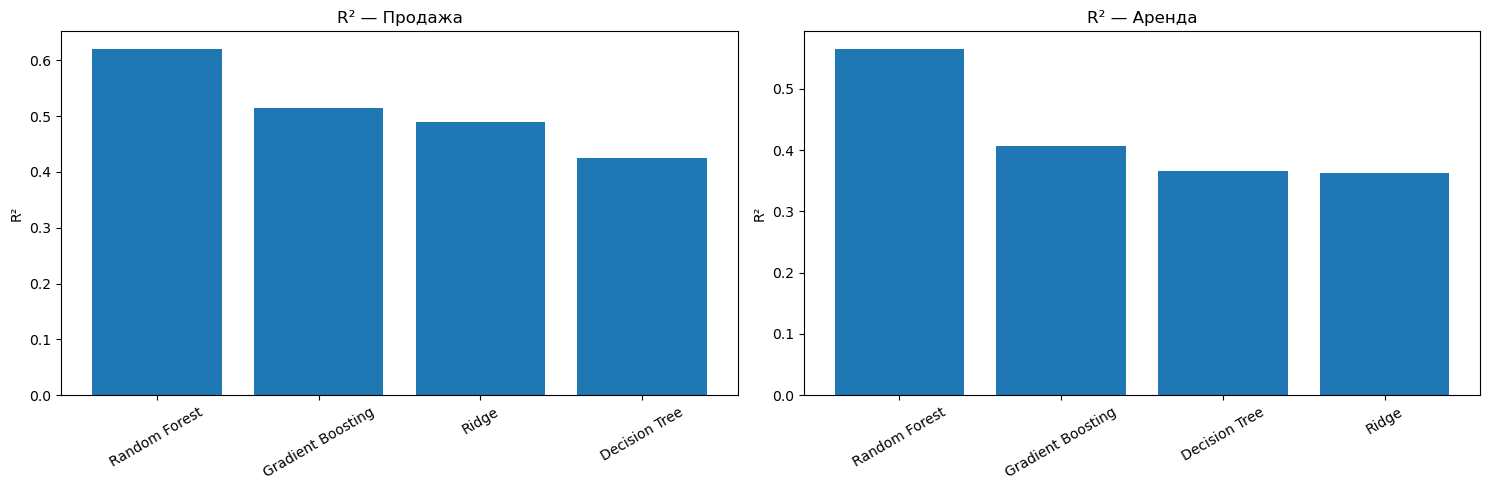

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for task_name, ax in [("Продажа", axes[0]), ("Аренда", axes[1])]:
    part = comparison[comparison["Тип"] == task_name]
    ax.bar(part["Модель"], part["R2"])
    ax.set_title(f"R² — {task_name}")
    ax.set_ylabel("R²")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

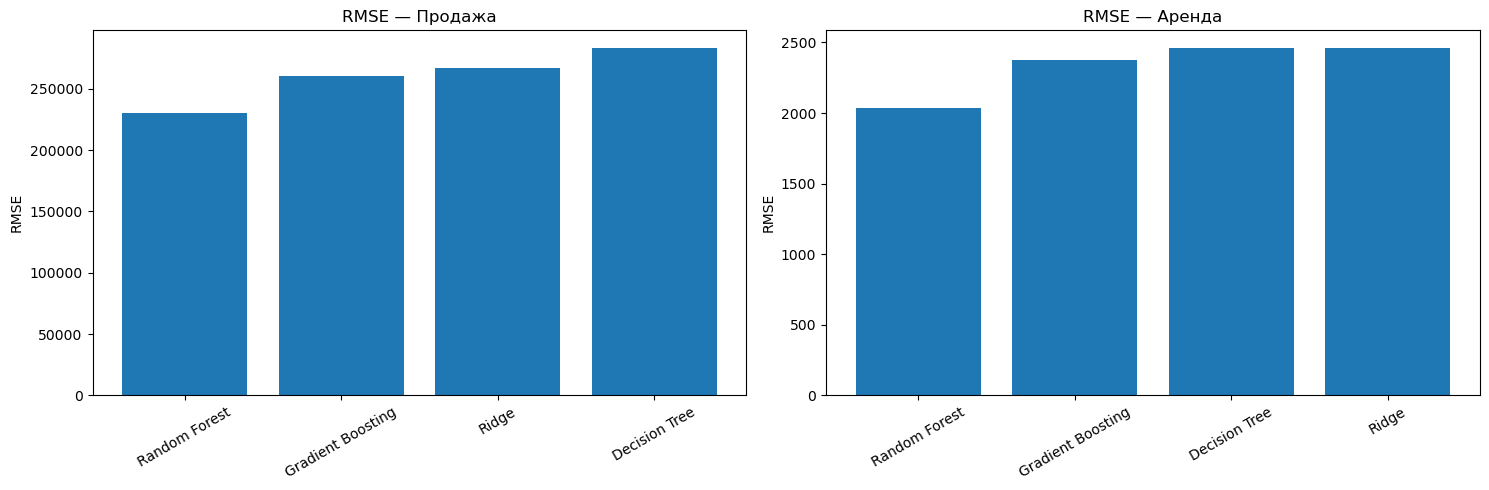

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for task_name, ax in [("Продажа", axes[0]), ("Аренда", axes[1])]:
    part = comparison[comparison["Тип"] == task_name]
    ax.bar(part["Модель"], part["RMSE"])
    ax.set_title(f"RMSE — {task_name}")
    ax.set_ylabel("RMSE")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 8. Фиксируем лучшую модель для каждой задачи

In [42]:
def choose_best_model(result_table):
    best_row = result_table.sort_values(
        ["RMSE", "R2"], ascending=[True, False]
    ).iloc[0]
    return best_row["Модель"]

best_sale_name = choose_best_model(sale_results)
best_rent_name = choose_best_model(rent_results)

print("Лучшая модель для продажи:", best_sale_name)
print("Лучшая модель для аренды:", best_rent_name)

Лучшая модель для продажи: Random Forest
Лучшая модель для аренды: Random Forest


## 9. Финальная модель на всех обучающих данных

Теперь нашу выбранную модель каждого типа обучаем **на всех доступных обучающих объектах**, а не только на подвыборке.

In [46]:
def build_final_model(model_name):
    if model_name == "Ridge":
        return Ridge(alpha=10.0)
    if model_name == "Decision Tree":
        return DecisionTreeRegressor(
            max_depth=20, min_samples_split=5, random_state=RANDOM_STATE
        )
    if model_name == "Random Forest":
        return RandomForestRegressor(
            n_estimators=100, max_depth=20,
            min_samples_split=5, random_state=RANDOM_STATE, n_jobs=-1
        )
    if model_name == "Gradient Boosting":
        return GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.05,
            max_depth=3, random_state=RANDOM_STATE
        )
    raise ValueError("Неизвестная модель")

final_sale_model = build_final_model(best_sale_name)
final_rent_model = build_final_model(best_rent_name)

final_sale_model.fit(sale_task["X_train"], sale_task["y_train"])
final_rent_model.fit(rent_task["X_train"], rent_task["y_train"])

sale_pred_holdout = final_sale_model.predict(sale_task["X_test"])
rent_pred_holdout = final_rent_model.predict(rent_task["X_test"])

In [47]:
print("Продажа:", calculate_metrics(sale_task["y_test"], sale_pred_holdout))

Продажа: {'MAE': 102317.92215577052, 'RMSE': np.float64(202879.72703102772), 'MAPE': np.float64(29.093240906039718), 'R2': 0.7056753530806744}


In [48]:
print("Аренда:", calculate_metrics(rent_task["y_test"], rent_pred_holdout))

Аренда: {'MAE': 721.9823952282627, 'RMSE': np.float64(1940.6351714027205), 'MAPE': np.float64(37.909355774307215), 'R2': 0.6041891490647651}


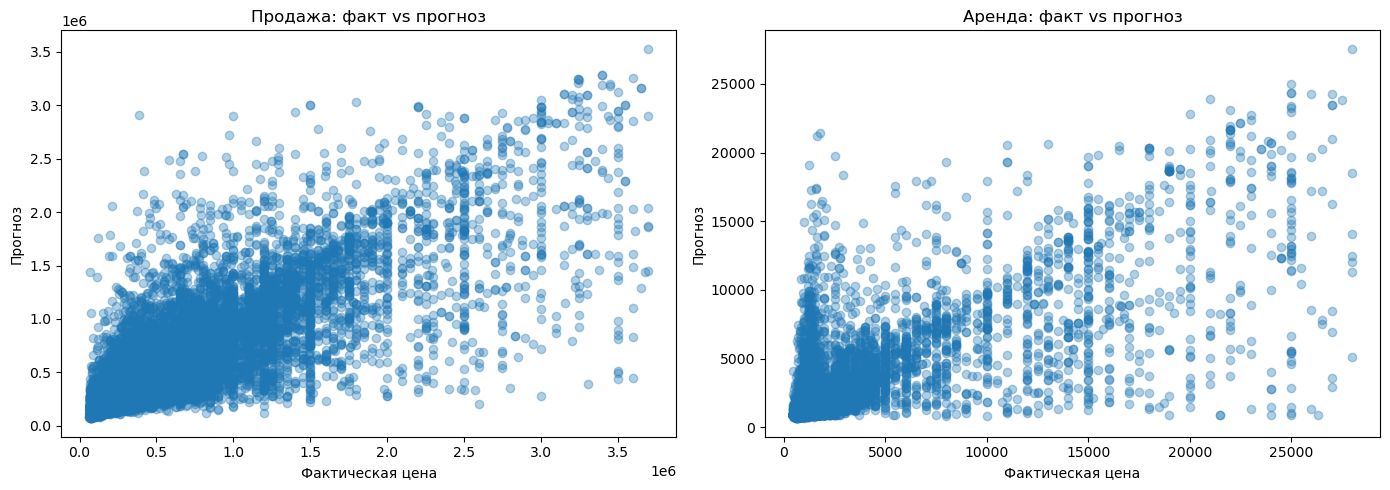

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(sale_task["y_test"], sale_pred_holdout, alpha=0.35)
axes[0].set_title("Продажа: факт vs прогноз")
axes[0].set_xlabel("Фактическая цена")
axes[0].set_ylabel("Прогноз")

axes[1].scatter(rent_task["y_test"], rent_pred_holdout, alpha=0.35)
axes[1].set_title("Аренда: факт vs прогноз")
axes[1].set_xlabel("Фактическая цена")
axes[1].set_ylabel("Прогноз")

plt.tight_layout()
plt.show()

## 10. Проверка на 20 тестовых объектах

In [50]:
test_ids = set(test_samples["id"].dropna())

# Полностью исключаем тестовые объекты из обучения
sale_train_full = sale_clean[~sale_clean["id"].isin(test_ids)].copy()
rent_train_full = rent_clean[~rent_clean["id"].isin(test_ids)].copy()

print("Продаж для финального обучения:", len(sale_train_full))
print("Аренд для финального обучения:", len(rent_train_full))
print("Тестовых объектов:", len(test_samples))

Продаж для финального обучения: 278796
Аренд для финального обучения: 111772
Тестовых объектов: 20


In [53]:
# Строим признаки для train и теста отдельно, но категории берём только из train
X_sale_train_final, sale_categories = make_features(sale_train_full)
X_rent_train_final, rent_categories = make_features(rent_train_full)

X_sale_test_final, _ = make_features(test_samples[test_samples["listing_type"] == SALE], sale_categories)
X_rent_test_final, _ = make_features(test_samples[test_samples["listing_type"] == RENT], rent_categories)

# Согласуем набор столбцов
X_sale_test_final = X_sale_test_final.reindex(
    columns=X_sale_train_final.columns, fill_value=0
)
X_rent_test_final = X_rent_test_final.reindex(
    columns=X_rent_train_final.columns, fill_value=0
)

y_sale_train_final = sale_train_full["price"].astype(float).to_numpy()
y_rent_train_final = rent_train_full["price"].astype(float).to_numpy()

# Imputer и scaler обучаются только на train
sale_imp_final = SimpleImputer(strategy="median")
rent_imp_final = SimpleImputer(strategy="median")

X_sale_train_imp = sale_imp_final.fit_transform(X_sale_train_final)
X_sale_test_imp = sale_imp_final.transform(X_sale_test_final)

X_rent_train_imp = rent_imp_final.fit_transform(X_rent_train_final)
X_rent_test_imp = rent_imp_final.transform(X_rent_test_final)

sale_scaler_final = RobustScaler()
rent_scaler_final = RobustScaler()

X_sale_train_scaled = sale_scaler_final.fit_transform(X_sale_train_imp)
X_sale_test_scaled = sale_scaler_final.transform(X_sale_test_imp)

X_rent_train_scaled = rent_scaler_final.fit_transform(X_rent_train_imp)
X_rent_test_scaled = rent_scaler_final.transform(X_rent_test_imp)

print("Продажа:", X_sale_train_scaled.shape, "тест:", X_sale_test_scaled.shape)
print("Аренда:", X_rent_train_scaled.shape, "тест:", X_rent_test_scaled.shape)

Продажа: (278796, 109) тест: (10, 109)
Аренда: (111772, 109) тест: (10, 109)


In [54]:
# Обучаем финальные модели на ВСЕХ доступных train-данных
final_sale_test_model = build_final_model(best_sale_name)
final_rent_test_model = build_final_model(best_rent_name)

final_sale_test_model.fit(X_sale_train_scaled, y_sale_train_final)
final_rent_test_model.fit(X_rent_train_scaled, y_rent_train_final)

sale_test_mask = test_samples["listing_type"] == SALE
rent_test_mask = test_samples["listing_type"] == RENT

sale_test_predictions = final_sale_test_model.predict(X_sale_test_scaled)
rent_test_predictions = final_rent_test_model.predict(X_rent_test_scaled)

print("Прогнозов продажи:", len(sale_test_predictions))
print("Прогнозов аренды:", len(rent_test_predictions))

Прогнозов продажи: 10
Прогнозов аренды: 10


## 11. Итоговая таблица из 20 объектов

In [56]:
result_test = test_samples.copy()

result_test["ФИО"] = "Маликова Камалия Илшатовна"
result_test["Группа"] = "23П-1"
result_test["Тип модели"] = np.where(
    result_test["listing_type"] == SALE, "Продажа", "Аренда"
)
result_test["Прогноз модели (TRY)"] = np.nan

result_test.loc[sale_test_mask, "Прогноз модели (TRY)"] = sale_test_predictions
result_test.loc[rent_test_mask, "Прогноз модели (TRY)"] = rent_test_predictions

result_test["Абсолютная ошибка (TRY)"] = np.abs(
    result_test["price"] - result_test["Прогноз модели (TRY)"]
)

display(result_test)

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,...,address,furnished,heating_type,price,price_currency,ФИО,Группа,Тип модели,Прогноз модели (TRY),Абсолютная ошибка (TRY)
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,...,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,2.902934e+05,9.706634e+03
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,...,İzmir/Foça/Yeniköy,NaN,Yok,1600000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,1.532340e+06,6.766030e+04
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,...,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,7.028059e+05,2.128059e+05
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,...,Tekirdağ/Çerkezköy/Kızılpınar,NaN,Yok,103600.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,2.026146e+05,9.901457e+04
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,...,İzmir/Aliağa/Yenişakran,NaN,Fancoil,300000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,2.902934e+05,9.706634e+03
5,100,Konut,Yazlık,1/12/19,NaN,1,46,1,10,9,...,Mersin/Erdemli/Kargıpınarı,NaN,Fancoil,500000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,3.240051e+05,1.759949e+05
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,...,Balıkesir/Burhaniye/Pelitköy,NaN,Fancoil,1000000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,4.138091e+05,5.861909e+05
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,...,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,2.481593e+05,9.315928e+04
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,NaN,4,NaN,...,İzmir/Konak/Akın Simav,NaN,Kalorifer (Doğalgaz),650000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,7.805613e+05,1.305613e+05
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,...,Muğla/Bodrum/Ortakentyahşi,NaN,Fancoil,2450000.0,TRY,Маликова Камалия Илшатовна,23П-1,Продажа,6.543555e+05,1.795645e+06


## 12. MAE, RMSE и R² на 20 тестовых объектах

In [57]:
y_test_20 = result_test["price"].astype(float).to_numpy()
y_pred_20 = result_test["Прогноз модели (TRY)"].astype(float).to_numpy()

# Метрики для всех 20 объектов вместе
metrics_20_sklearn = calculate_metrics(y_test_20, y_pred_20)
metrics_20_manual = manual_metrics(y_test_20, y_pred_20)

# Отдельно продажа и аренда
sale_result_part = result_test[result_test["listing_type"] == SALE]
rent_result_part = result_test[result_test["listing_type"] == RENT]

sale_metrics = calculate_metrics(
    sale_result_part["price"].to_numpy(),
    sale_result_part["Прогноз модели (TRY)"].to_numpy()
)
rent_metrics = calculate_metrics(
    rent_result_part["price"].to_numpy(),
    rent_result_part["Прогноз модели (TRY)"].to_numpy()
)

In [58]:
print("Продажа")
print(sale_metrics)

Продажа
{'MAE': 318044.4864219605, 'RMSE': np.float64(607002.0337050067), 'MAPE': np.float64(39.70023263601342), 'R2': 0.26187498754585214}


In [59]:
print("Аренда")
print(rent_metrics)

Аренда
{'MAE': 4441.924797464193, 'RMSE': np.float64(7528.473693910635), 'MAPE': np.float64(43.23234826018529), 'R2': -0.4861894714735644}


In [60]:
print("\n 20 обьектов")
print(metrics_20_sklearn)


 20 обьектов
{'MAE': 161243.20560971234, 'RMSE': np.float64(429248.2654817454), 'MAPE': np.float64(41.46629044809935), 'R2': 0.5269470062802599}


In [62]:
print("Ручной расчет для всех 20 обьектов ")
print("MAE =", metrics_20_manual[0])
print("RMSE =", metrics_20_manual[1])
print("R2 =", metrics_20_manual[2])

Ручной расчет для всех 20 обьектов 
MAE = 161243.20560971234
RMSE = 429248.2654817454
R2 = 0.5269470062802599


### Проверка ручного расчёта


Ручные формулы:

\[
MAE = \frac{1}{n}\sum |y_i-\hat y_i|
\]

\[
RMSE = \sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}
\]

\[
R^2 = 1 - \frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}
\]

Результаты ручного расчёта должны совпадать со `sklearn` с точностью до округления.

In [63]:
manual_table = pd.DataFrame({
    "Метрика": ["MAE", "RMSE", "R2"],
    "Вручную": list(metrics_20_manual),
    "sklearn": [
        metrics_20_sklearn["MAE"],
        metrics_20_sklearn["RMSE"],
        metrics_20_sklearn["R2"]
    ]
})

manual_table["Разница"] = manual_table["Вручную"] - manual_table["sklearn"]
display(manual_table)

,Метрика,Вручную,sklearn,Разница
0,MAE,161243.205610,161243.205610,0.0
1,RMSE,429248.265482,429248.265482,0.0
2,R2,0.526947,0.526947,0.0


## 13. Визуализация ошибок на 20 тестовых объектах

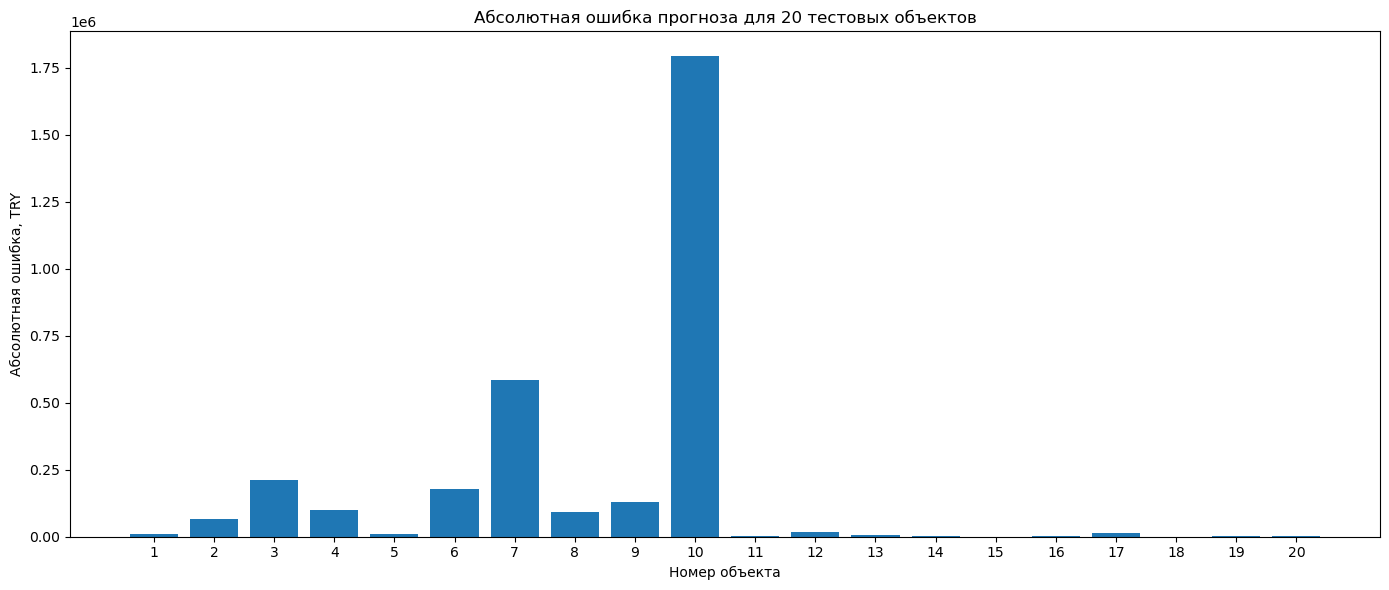

In [64]:
plot_df = result_test.copy()
plot_df["Объект"] = np.arange(1, len(plot_df) + 1)

plt.figure(figsize=(14, 6))
plt.bar(
    plot_df["Объект"],
    plot_df["Абсолютная ошибка (TRY)"]
)
plt.xlabel("Номер объекта")
plt.ylabel("Абсолютная ошибка, TRY")
plt.title("Абсолютная ошибка прогноза для 20 тестовых объектов")
plt.xticks(plot_df["Объект"])
plt.tight_layout()
plt.show()

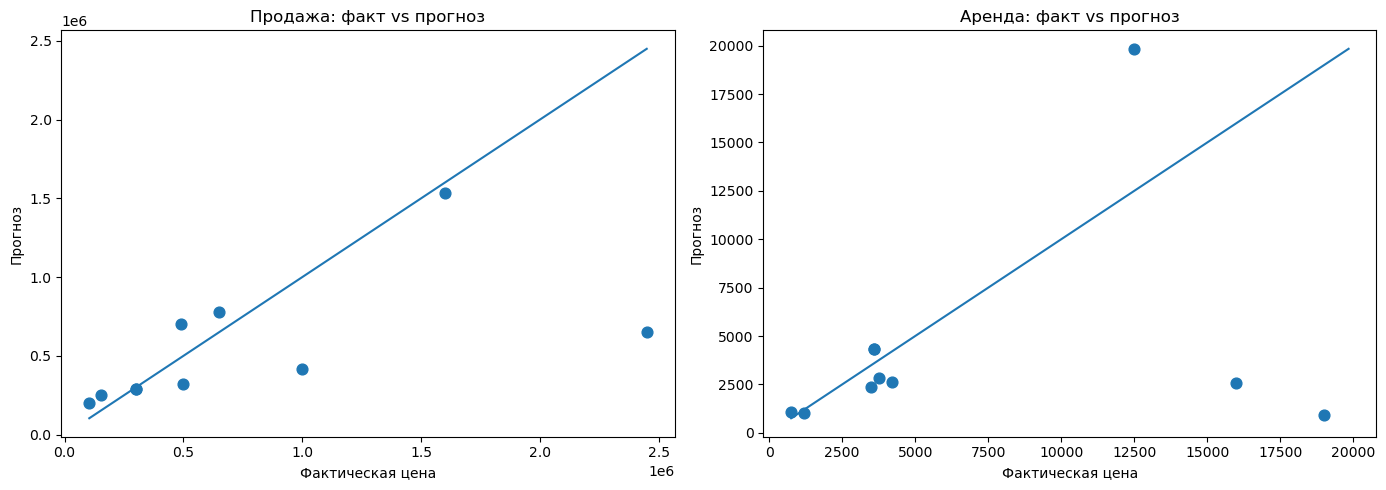

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for task_name, mask, ax in [
    ("Продажа", result_test["listing_type"] == SALE, axes[0]),
    ("Аренда", result_test["listing_type"] == RENT, axes[1])
]:
    part = result_test.loc[mask]
    ax.scatter(part["price"], part["Прогноз модели (TRY)"], s=60)
    min_v = min(part["price"].min(), part["Прогноз модели (TRY)"].min())
    max_v = max(part["price"].max(), part["Прогноз модели (TRY)"].max())
    ax.plot([min_v, max_v], [min_v, max_v])
    ax.set_title(f"{task_name}: факт vs прогноз")
    ax.set_xlabel("Фактическая цена")
    ax.set_ylabel("Прогноз")

plt.tight_layout()
plt.show()

## 14. Итоговое сравнение продажи и аренды

In [66]:
summary = pd.DataFrame([
    ["Продажа", best_sale_name, sale_metrics["MAE"], sale_metrics["RMSE"], sale_metrics["R2"]],
    ["Аренда", best_rent_name, rent_metrics["MAE"], rent_metrics["RMSE"], rent_metrics["R2"]]
], columns=["Тип", "Лучшая модель", "MAE", "RMSE", "R2"])

display(summary)

,Тип,Лучшая модель,MAE,RMSE,R2
0,Продажа,Random Forest,318044.486422,607002.033705,0.261875
1,Аренда,Random Forest,4441.924797,7528.473694,-0.486189


## 15. Сохранение результата

In [ ]:
result_test.to_csv("result_real_estate_samples.csv", index=False, encoding="utf-8-sig")

print("Файл result_real_estate_samples_dual.csv сохранён.")

## 16. Что сказать на защите

**Почему две модели?**  
Потому что цена продажи и арендная плата имеют разный экономический смысл и разные масштабы. Поэтому для каждой задачи строится отдельная регрессионная модель.

**Что такое X?**  
`X` — характеристики объекта: площадь, комнаты, возраст здания, этаж, тип недвижимости, отопление, город и другие признаки.

**Что такое y?**  
Для продажи `y` — цена продажи. Для аренды `y` — арендная плата.

**Зачем train/test split?**  
Чтобы оценивать модель на данных, которых она не видела при обучении.

**Зачем медианная импутация?**  
Чтобы заполнить пропуски устойчивым к выбросам значением. Медиана вычисляется только по обучающей части.

**Зачем RobustScaler?**  
Он масштабирует числовые признаки через медиану и межквартильный размах и поэтому устойчивее к выбросам.

**Почему Random Forest может оказаться лучше линейной модели?**  
Потому что цена недвижимости зависит от признаков нелинейно: площадь, город, этаж и тип недвижимости взаимодействуют между собой.

**Что означает R²?**  
Например, R² = 0.60 означает, что модель объясняет около 60% вариации цен на соответствующей тестовой выборке. Это не процент правильных ответов.

**Почему выбросы удаляются отдельно для продажи и аренды?**  
Потому что общий порог по цене был бы некорректен: арендные платежи значительно ниже цен продажи.